In [3]:
import pandas as pd
import matplotlib.pyplot as plt

import sys, os, sqlite3

sys.path.insert(0, os.path.join(os.getcwd(), '..'))
from framework import init_env
init_env()

path = os.path.join("..", os.environ["DB_FILE"])
database = sqlite3.connect(path)


In [9]:
artist = "%Borsato%"

sql = 'SELECT rowid, * FROM Artist WHERE name LIKE "%s"' % artist 
dfa = pd.read_sql_query(sql, database)
dfa

,rowid,name
0,1021,Marco Borsato
1,1022,Marco Borsato & Ali B
2,1023,Marco Borsato & Do
3,1024,Marco Borsato & Lucie Silvas
4,1025,Marco Borsato & Trijntje Oosterhuis
5,1974,"Marco Borsato, Armin van Buuren & Davina Michelle"


In [10]:
sql = """
    SELECT A.name, S.title, S.year, O.edition, O.position
    FROM Occurance O
    INNER JOIN Song S ON S.rowid = O.song
    INNER JOIN Artist A ON A.rowid = S.artist
    WHERE A.rowid IN (%s)
""" % ", ".join(str(e) for e in dfa['rowid'].values.tolist())
df = pd.read_sql_query(sql, database)
df

,name,title,year,edition,position
0,Marco Borsato,Dochters,2008,2009,25
1,Marco Borsato,Dochters,2008,2010,31
2,Marco Borsato,Dochters,2008,2011,42
3,Marco Borsato,Dochters,2008,2012,47
4,Marco Borsato,Dochters,2008,2013,72
...,...,...,...,...,...
322,"Marco Borsato, Armin van Buuren & Davina Michelle",Hoe Het Danst,2019,2021,526
323,"Marco Borsato, Armin van Buuren & Davina Michelle",Hoe Het Danst,2019,2022,1366
324,"Marco Borsato, Armin van Buuren & Davina Michelle",Hoe Het Danst,2019,2023,1180
325,"Marco Borsato, Armin van Buuren & Davina Michelle",Hoe Het Danst,2019,2024,1261


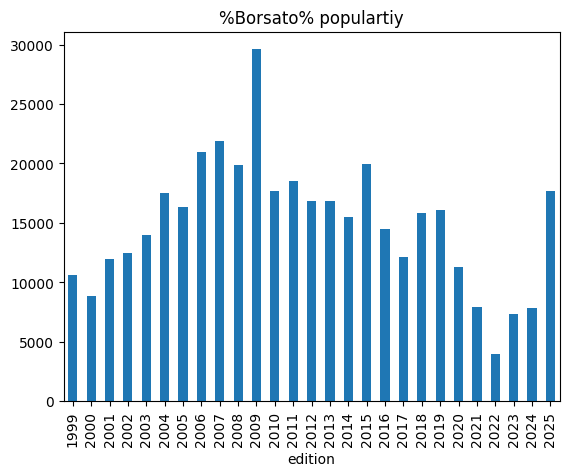

In [11]:
sql = """
    SELECT Y.edition, S.score
    FROM (
        SELECT DISTINCT edition FROM Occurance
    ) Y
    LEFT JOIN ( 
        SELECT O.edition, SUM(2000 - position) AS score
        FROM Occurance O
        INNER JOIN Song S ON S.rowid = O.song
        INNER JOIN Artist A ON A.rowid = S.artist
        WHERE A.rowid IN (%s)
        GROUP BY O.edition
    ) S ON S.edition = Y.edition
""" % ", ".join(str(e) for e in dfa['rowid'].values.tolist())
df = pd.read_sql_query(sql, database)
df = df.fillna(0)
df = df.set_index('edition')
ax = df.plot.bar(title="{} populartiy".format(artist), legend=False)
plt.show()

In [12]:
sql = "SELECT rowid, title, year FROM Song WHERE artist IN (%s)" % ", ".join(str(e) for e in dfa['rowid'].values.tolist())
dfs = pd.read_sql_query(sql, database).set_index('rowid')

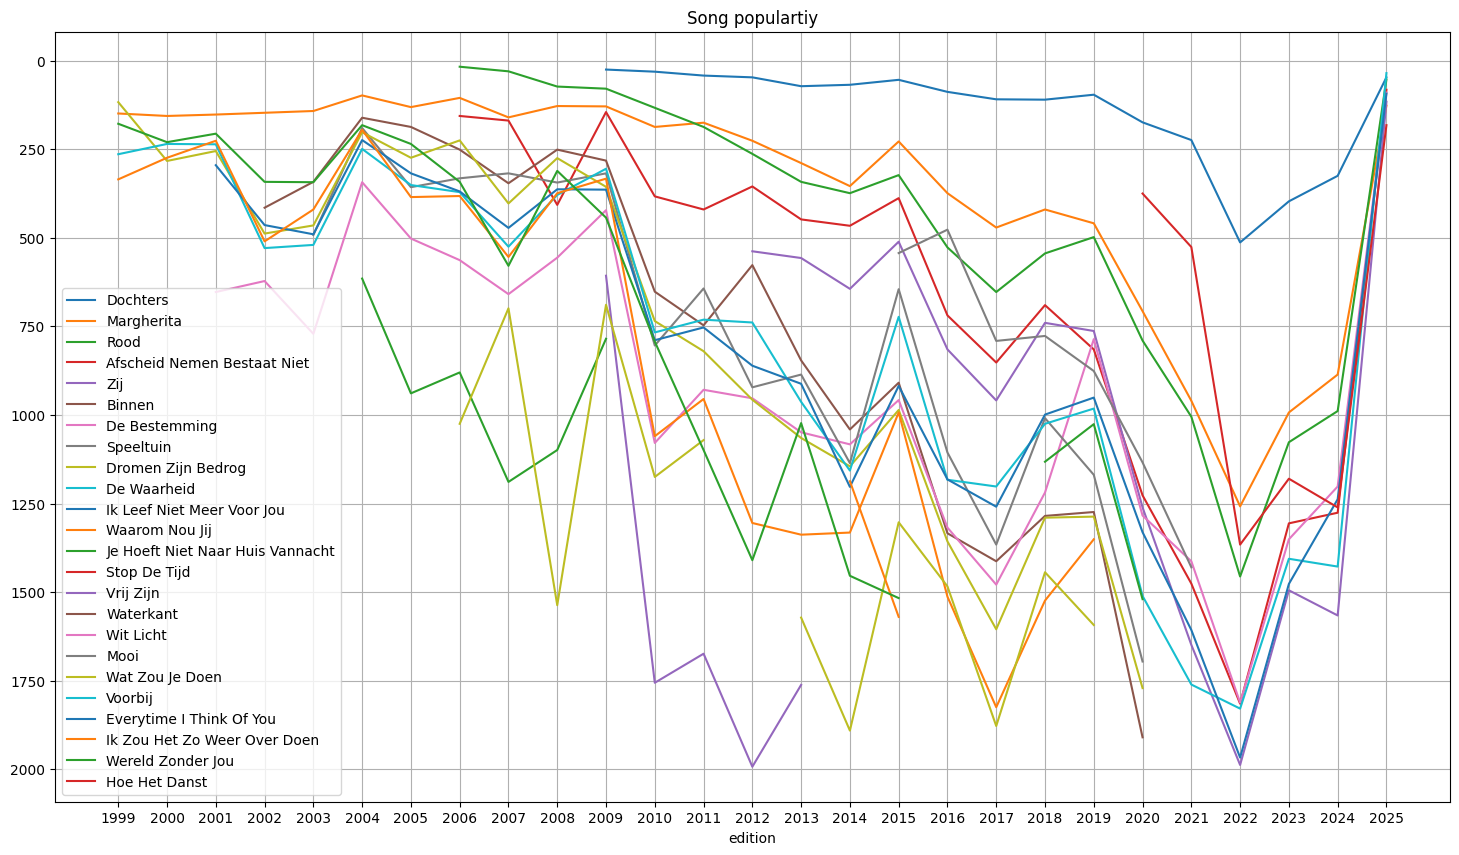

In [15]:
def get_song_score(song_id, song_title):
    sql = """
        SELECT Y.edition, S.position
        FROM (
            SELECT DISTINCT edition FROM Occurance
        ) Y
        LEFT JOIN ( 
            SELECT O.edition, position 
            FROM Occurance O
            INNER JOIN Song S ON S.rowid = O.song
            WHERE S.rowid = %d
            GROUP BY O.edition
        ) S ON S.edition = Y.edition
    """ % song_id
    return pd.read_sql_query(sql, database).set_index('edition').rename(columns={'position' : song_title})

is_first = True


for index, row in dfs.iterrows():
    title = row['title']
    dft = get_song_score(index, title)
    if (is_first):
        dfr = dft
        is_first = False
    else:
        dfr[title] = dft[title]
    
ax = dfr.plot(figsize=(18, 10), title="Song populartiy", xticks=range(1999, 2026), grid=True).invert_yaxis()

#dfr